In [14]:
import numpy as np
from torchvision import datasets
import matplotlib.pyplot as plt

In [15]:
class my_relu:
    def __init__(self):
        pass

    def forward(self, x):
        return np.maximum(0, x)

    def backward(self, x, dL):
        return dL * (x > 0).astype(x.dtype)

class my_SoftmaxCrossEntropy:
    def _log_softmax(self, logits):
        shifted = logits - np.max(
            logits, axis=1, keepdims=True
        )

        return shifted - np.log(
            np.sum(
                np.exp(shifted),
                axis=1,
                keepdims=True
            )
        )

    def forward(self, logits, y):
        log_probs = self._log_softmax(logits)

        loss_per_image = -np.sum(
            y * log_probs,
            axis=1
        )

        return np.mean(loss_per_image)

    def backward(self, logits, y):
        bs = logits.shape[0]

        log_probs = self._log_softmax(logits)
        probs = np.exp(log_probs)

        return (probs - y) / bs

In [16]:
train_ds = datasets.MNIST(root='data', train=True, download=True)
test_ds = datasets.MNIST(root='data', train=False, download=True)

X_train = train_ds.data.numpy()
y_train = train_ds.targets.numpy()

X_test = test_ds.data.numpy()
y_test = test_ds.targets.numpy()

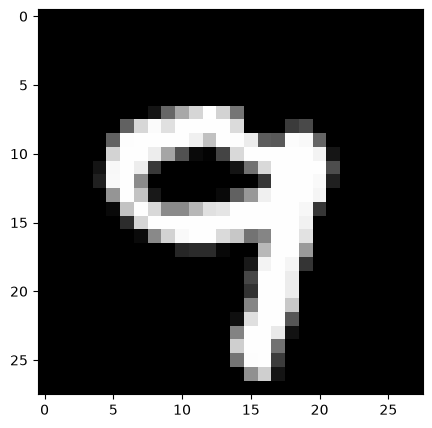

Изображение с истинной меткой:  9


In [17]:
random_index = np.random.randint(0, len(X_train))

plt.figure(figsize=(5, 5))
plt.imshow(X_train[random_index], cmap='gray')

plt.show()
print('Изображение с истинной меткой: ', y_train[random_index])

In [18]:
mean = X_train.mean()
std = X_train.std()

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

In [19]:
X_train = X_train.astype(np.float32).reshape(-1, 784)
X_test = X_test.astype(np.float32).reshape(-1, 784)

def to_one_hot(y, classes_num=10):
    out = np.zeros((len(y), classes_num), dtype=np.float32)
    out[np.arange(len(y)), y] = 1.0
    return out

y_train = to_one_hot(y_train)
y_test = to_one_hot(y_test)

In [20]:
rng = np.random.default_rng(42)
perm = rng.permutation(len(X_train))
train_idx, val_idx = perm[:50000], perm[50000:]

In [25]:
class Linear:
    def __init__(self, in_features, out_features):
        self.W = (
            np.random.randn(in_features, out_features)
            * np.sqrt(2.0 / in_features)
        )
        self.b = np.zeros((1, out_features))

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dL_dout, lr=0.01):
        dL_db = np.sum(dL_dout, axis=0, keepdims=True)
        dL_dw = self.x.T @ dL_dout

        dL_dx = dL_dout @ self.W.T
        self.W -= lr * dL_dw
        self.b -= lr * dL_db

        return dL_dx

In [26]:
lin_1 = Linear(X_train.shape[1], 8)
lin_2 = Linear(8, 10)

In [37]:
epoches = 100

for epoch in range(epoches):
    l1 = lin_1.forward(X_train[train_idx])
    l1_relu = my_relu().forward(l1)

    l2 = lin_2.forward(l1_relu)

    loss = my_SoftmaxCrossEntropy().forward(l2, y_train[train_idx])

    dL_dl2 = my_SoftmaxCrossEntropy().backward(l2, y_train[train_idx])

    dL_dl1_relu = lin_2.backward(dL_dl2)

    dL_dl1 = my_relu().backward(l1, dL_dl1_relu)

    lin_1.backward(dL_dl1)

    print(f'Epoch {epoch + 1}/{epoches} loss: {loss}')

Epoch 1/100 loss: 1.634293597603617
Epoch 2/100 loss: 1.6306948170668334
Epoch 3/100 loss: 1.6271194854621756
Epoch 4/100 loss: 1.6235678872424566
Epoch 5/100 loss: 1.6200338691186706
Epoch 6/100 loss: 1.6165169947550475
Epoch 7/100 loss: 1.613010508051244
Epoch 8/100 loss: 1.6095205524761707
Epoch 9/100 loss: 1.6060529529718717
Epoch 10/100 loss: 1.602605627579717
Epoch 11/100 loss: 1.59917625174887
Epoch 12/100 loss: 1.5957614756669232
Epoch 13/100 loss: 1.5923632012204318
Epoch 14/100 loss: 1.5889841264544098
Epoch 15/100 loss: 1.5856245339408592
Epoch 16/100 loss: 1.5822827804152564
Epoch 17/100 loss: 1.5789575390766224
Epoch 18/100 loss: 1.5756468431108877
Epoch 19/100 loss: 1.572349774533656
Epoch 20/100 loss: 1.5690681228942922
Epoch 21/100 loss: 1.565802371311992
Epoch 22/100 loss: 1.5625518034447095
Epoch 23/100 loss: 1.5593141632156546
Epoch 24/100 loss: 1.5560864055550383
Epoch 25/100 loss: 1.5528712909046858
Epoch 26/100 loss: 1.5496692788333903
Epoch 27/100 loss: 1.5464788

Изображение с предсказанной меткой:  [0]
Истинная метка:  [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


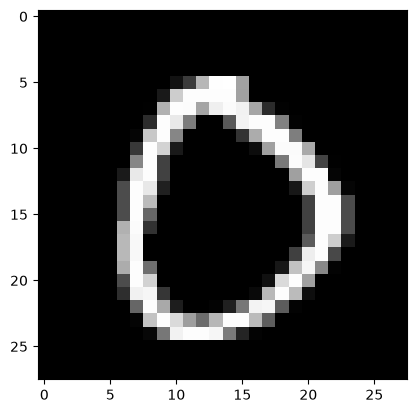

In [54]:
test_id = np.random.randint(0, len(X_test))

l1 = lin_1.forward(X_test[test_id])
l1_relu = my_relu().forward(l1)

l2 = lin_2.forward(l1_relu)

pred = np.argmax(l2, axis=1)

plt.imshow(X_test[test_id].reshape(28, 28), cmap='gray')

print('Изображение с предсказанной меткой: ', pred)
print('Истинная метка: ', y_test[test_id])